In [1]:
from dataclasses import asdict

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from vasijas.config import load_config
from vasijas.paths import ProjectPaths, ruta_relativa
from vasijas.metadata import cargar_metadata
from vasijas.evaluacion import (
    cargar_modelo_resnet18_evaluacion,
    crear_loader_test_con_ruta,
    validar_identificadores_split,
)
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    crear_datasets_imagen_desde_metadata,
    crear_transformaciones_imagen,
    seleccionar_dispositivo_procesamiento,
)
from vasijas.umap_evaluacion import (
    ConfiguracionUmap,
    extraer_caracteristicas_test,
    proyectar_caracteristicas_umap,
    graficar_umap_test,
    guardar_resultado_umap,
)

# UMAP del conjunto de prueba

Este reporte explora las características visuales de las imágenes con `split == "test"` en `data/12.unificado_divididos_en_train_val_y_test/metadata.csv`. La lógica se implementa en `vasijas.umap_evaluacion`; el notebook configura, orquesta y presenta los resultados para Quarto.

Se utiliza la misma ResNet18 del notebook 15, con sus pesos locales. Cada punto representa una imagen mediante las 512 características de la capa `avgpool`, anteriores al clasificador. Las clases reales solo determinan el color: UMAP se ajusta sin etiquetas y únicamente sobre test.

## Configuración

In [2]:
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)
DATA_DIR = PATHS.DATA_UNIFICADO_DIVIDIDO
MODEL_PATH = (
    PATHS.OUTPUT_MODELS
    / "model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth"
)
OUTPUT_DIR = PATHS.OUTPUT_UMAP
CSV_PATH = OUTPUT_DIR / f"umap_test_{MODEL_PATH.stem}.csv"
FIGURE_PATH = OUTPUT_DIR / f"umap_test_{MODEL_PATH.stem}.png"
BATCH_SIZE = 16
TAMANO_IMAGEN = 224
UMAP_CONFIG = ConfiguracionUmap(
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42,
)
DEVICE = seleccionar_dispositivo_procesamiento()

pd.DataFrame([{
    "metadata": str(ruta_relativa(DATA_DIR / "metadata.csv")),
    "modelo": MODEL_PATH.name,
    "dispositivo": str(DEVICE),
    "batch_size": BATCH_SIZE,
    "tamano_imagen": TAMANO_IMAGEN,
    **asdict(UMAP_CONFIG),
}])

,metadata,modelo,dispositivo,batch_size,tamano_imagen,n_neighbors,min_dist,metric,random_state
0,data/12.unificado_divididos_en_train_val_y_tes...,model_resnet18_unificado_bs16_lr1e-3_weighted_...,cuda,16,224,15,0.1,cosine,42


## Preparación de los datos

Se reutiliza la división persistida, sin volver a dividir ni muestrear las imágenes. El preprocesamiento es el de evaluación del notebook 15: tamaño 224 × 224 y normalización ImageNet sin aumentación. Se comprueba la correspondencia entre archivos, rutas, clases y metadata antes de extraer características.

In [3]:
metadata_split = cargar_metadata(DATA_DIR)
validar_identificadores_split(metadata_split)
transformaciones = crear_transformaciones_imagen(
    ConfiguracionTransformacionesImagen(tamano_imagen=TAMANO_IMAGEN)
)
datasets_imagen = crear_datasets_imagen_desde_metadata(
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    transformacion_entrenamiento=transformaciones[0],
    transformacion_validacion=transformaciones[1],
    transformacion_test=transformaciones[2],
)
nombres_clases = datasets_imagen.class_names
test_loader = crear_loader_test_con_ruta(
    subset=datasets_imagen.test,
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    batch_size=BATCH_SIZE,
    dispositivo=DEVICE,
)
metadata_test = metadata_split.loc[metadata_split["split"].eq("test")]
display(
    metadata_test.groupby("clase_carpeta").size().rename("imagenes_test").to_frame()
)
print(f"Total de imágenes de prueba: {len(metadata_test)}")

,imagenes_test
clase_carpeta,
clase01,76
clase02,133
clase03,209
clase05,152
clase06,152
clase07,133
clase08,798
clase09,57
clase10,1007


Total de imágenes de prueba: 3059


## Extracción de características

La red se ejecuta en modo de evaluación y sin gradientes. Se conserva una fila de metadata por vector mediante la ruta de la imagen, incluyendo el último lote incompleto. Las características permanecen en memoria para poder reutilizarlas al cambiar los parámetros de UMAP.

In [4]:
modelo = cargar_modelo_resnet18_evaluacion(
    ruta_modelo=MODEL_PATH,
    nombres_clases=nombres_clases,
    dispositivo=DEVICE,
)
caracteristicas_test, metadata_caracteristicas = extraer_caracteristicas_test(
    modelo=modelo,
    test_loader=test_loader,
    metadata_split=metadata_split,
    nombres_clases=nombres_clases,
    dispositivo=DEVICE,
)
print(f"Matriz de características verificada: {caracteristicas_test.shape}")

Matriz de características verificada: (3059, 512)


## Proyección y visualización

Se ajusta una proyección bidimensional con distancia coseno, semilla fija y un solo trabajo para reproducir el ajuste en el mismo entorno. Las variables tabulares, los identificadores y las clases no se usan como entradas de UMAP.

Esta figura es exploratoria: la separación visual no mide la precisión del clasificador. La proyección se ajusta sobre test y no define un espacio de referencia aprendido en train.

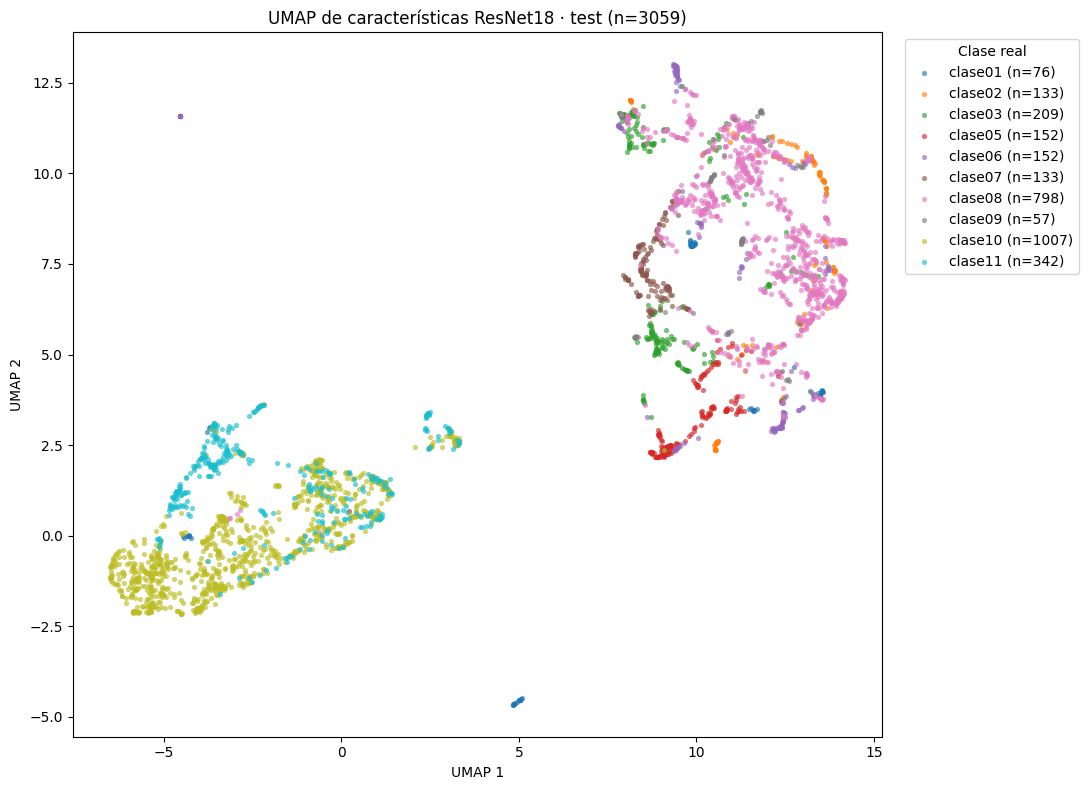

In [7]:
tabla_umap = proyectar_caracteristicas_umap(
    caracteristicas=caracteristicas_test,
    metadata_test=metadata_caracteristicas,
    configuracion=UMAP_CONFIG,
)
figura_umap = graficar_umap_test(tabla_umap)
display(figura_umap)
plt.close(figura_umap)

## Exportación

El CSV conserva las columnas y los valores faltantes de la metadata de prueba e incorpora `UMAP_1` y `UMAP_2`. El PNG exporta la misma figura del reporte. Este notebook está incluido en la configuración y el índice del sitio Quarto.

In [6]:
rutas_guardadas = guardar_resultado_umap(
    tabla=tabla_umap,
    figura=figura_umap,
    ruta_csv=CSV_PATH,
    ruta_figura=FIGURE_PATH,
)
display(tabla_umap[[
    "Identificador", "ruta_relativa", "clase_carpeta", "split", "UMAP_1", "UMAP_2"
]].head(10))
for ruta in rutas_guardadas:
    print(f"Archivo generado: {ruta_relativa(ruta)}")

,Identificador,ruta_relativa,clase_carpeta,split,UMAP_1,UMAP_2
0,ba_191_4,clase01/ba_191_4.png,clase01,test,4.946492,-4.583870
1,ba_191_4_base_10_centrado,clase01/ba_191_4_base_10_centrado.png,clase01,test,4.865473,-4.641615
2,ba_191_4_base_20_centrado,clase01/ba_191_4_base_20_centrado.png,clase01,test,4.869857,-4.637319
3,ba_191_4_base_30_centrado,clase01/ba_191_4_base_30_centrado.png,clase01,test,4.844340,-4.641831
4,ba_191_4_base_40_centrado,clase01/ba_191_4_base_40_centrado.png,clase01,test,4.844605,-4.659423
5,ba_191_4_base_50_centrado,clase01/ba_191_4_base_50_centrado.png,clase01,test,4.858972,-4.646490
6,ba_191_4_base_60_centrado,clase01/ba_191_4_base_60_centrado.png,clase01,test,4.844973,-4.661593
7,ba_191_4_base_70_centrado,clase01/ba_191_4_base_70_centrado.png,clase01,test,4.852363,-4.649289
8,ba_191_4_base_80_centrado,clase01/ba_191_4_base_80_centrado.png,clase01,test,4.871118,-4.639658
9,ba_191_4_base_90_centrado,clase01/ba_191_4_base_90_centrado.png,clase01,test,4.896715,-4.625113


Archivo generado: output/umap/umap_test_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.csv
Archivo generado: output/umap/umap_test_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.png
